# Fairness and Bias in GNNs – Midterm baselines.  
*See README for instructions.*

Cell 0 - Results save to Google Drive so a disconnect loses nothing.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Cell 1 - Setup: Downloading the 5 datasets from the original authors’ GitHub repos.

In [2]:
import os, random, time
import numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

ROOT = '/content' if os.path.exists('/content') else '/tmp'
os.chdir(ROOT)
if not os.path.exists('nifty'):
    os.system('git clone -q --depth 1 https://github.com/chirag126/nifty.git')
if not os.path.exists('FairGNN'):
    os.system('git clone -q --depth 1 https://github.com/EnyanDai/FairGNN.git')
if not os.path.exists('nifty/dataset/credit/credit_edges.txt'):
    import zipfile
    zipfile.ZipFile('nifty/dataset/credit/credit_edges.txt.zip').extractall('nifty/dataset/credit')

# Results go to Google Drive if mounted (survives Colab disconnects), else local
RESULTS_DIR = '/content/drive/MyDrive/gnn_fairness' if os.path.exists('/content/drive/MyDrive') else f'{ROOT}/results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print('datasets ready | results ->', RESULTS_DIR)

datasets ready | results -> /content/drive/MyDrive/gnn_fairness


Cell 2 - Loading data: Following code cell produces the 4 things every graph-learning task needs:  
* X (one feature row per node)  
* y (labels)  
* s (sensitive attribute)  
* A (adjacency, i.e. who is connected to whom)  

The sensitive attribute is removed from the features (“fairness through unawareness”), so any bias that appears has to come in through proxies or edges. The train/val/test splits replicate the original papers’ code exactly.

In [3]:
N, F = f'{ROOT}/nifty/dataset', f'{ROOT}/FairGNN/dataset'
CFG = {
  'german':  dict(csv=f'{N}/german/german.csv',   edges=f'{N}/german/german_edges.txt', sens='Gender', label='GoodCustomer',      drop=['OtherLoansAtStore','PurposeOfLoan'], n_train=100),
  'credit':  dict(csv=f'{N}/credit/credit.csv',   edges=f'{N}/credit/credit_edges.txt', sens='Age',    label='NoDefaultNextMonth', drop=['Single'],                         n_train=6000),
  'bail':    dict(csv=f'{N}/bail/bail.csv',       edges=f'{N}/bail/bail_edges.txt',     sens='WHITE',  label='RECID',              drop=[],                                 n_train=100),
  'pokec_z': dict(csv=f'{F}/pokec/region_job.csv',   edges=f'{F}/pokec/region_job_relationship.txt',   sens='region', label='I_am_working_in_field', drop=['user_id'], n_train=500),
  'pokec_n': dict(csv=f'{F}/pokec/region_job_2.csv', edges=f'{F}/pokec/region_job_2_relationship.txt', sens='region', label='I_am_working_in_field', drop=['user_id'], n_train=500),
}

def load_dataset(name, sens_in_features=False):
    """Returns X (features), y (labels, -1 = unlabeled), s (sensitive 0/1),
    A (scipy sparse adjacency, symmetric, no self-loops), train/val/test node indices, feature names."""
    c = CFG[name]
    df = pd.read_csv(c['csv'])
    if name == 'german':
        df['Gender'] = (df['Gender'] == 'Female').astype(int)          # 1 = female
        df['GoodCustomer'] = (df['GoodCustomer'] == 1).astype(int)     # -1/1 -> 0/1
    y = df[c['label']].values.astype(int)
    s = df[c['sens']].values.astype(int)
    if name.startswith('pokec'):                                        # same binarisation as FairGNN
        y[y > 1] = 1
        s[s > 0] = 1

    drop = [c['label']] + c['drop'] + ([] if sens_in_features else [c['sens']])
    feats = df.drop(columns=drop)
    X = feats.values.astype(np.float32)
    lo, hi = X.min(0), X.max(0)
    X = 2 * (X - lo) / np.where(hi > lo, hi - lo, 1) - 1               # scale every column to [-1, 1]

    E = np.loadtxt(c['edges'], dtype=float).astype(int)
    if name.startswith('pokec'):                                        # pokec edges use user_ids, remap to rows
        idmap = {u: i for i, u in enumerate(df['user_id'].values)}
        E = np.vectorize(idmap.get)(E)
    n = len(df)
    A = sp.coo_matrix((np.ones(len(E)), (E[:, 0], E[:, 1])), shape=(n, n)).tocsr()
    A = ((A + A.T) > 0).astype(np.float32)
    A.setdiag(0); A.eliminate_zeros()

    # Splits follow the original papers' code exactly (fixed seed), so our numbers are comparable later
    # FairGNN's train_fairGNN.py passes seed=20 to load_pokec (verified identical splits)
    if name.startswith('pokec'):
        random.seed(20); idx = list(np.where(y >= 0)[0]); random.shuffle(idx); L = len(idx)
        tr, va, te = idx[:min(L // 2, c['n_train'])], idx[L // 2: 3 * L // 4], idx[3 * L // 4:]
    else:
        random.seed(20)
        i0, i1 = list(np.where(y == 0)[0]), list(np.where(y == 1)[0])
        random.shuffle(i0); random.shuffle(i1); h = c['n_train'] // 2
        tr = i0[:min(len(i0) // 2, h)] + i1[:min(len(i1) // 2, h)]
        va = i0[len(i0) // 2: 3 * len(i0) // 4] + i1[len(i1) // 2: 3 * len(i1) // 4]
        te = i0[3 * len(i0) // 4:] + i1[3 * len(i1) // 4:]
    return X, y, s, A, np.array(tr), np.array(va), np.array(te), list(feats.columns)

def normalized_adjacency(A):
    """GCN propagation matrix: D^-1/2 (A + I) D^-1/2. Multiplying by it = 'average over yourself + neighbours'."""
    A = A + sp.eye(A.shape[0], dtype=np.float32)
    d = np.asarray(A.sum(1)).ravel()
    Dinv = sp.diags(1.0 / np.sqrt(d))
    return (Dinv @ A @ Dinv).tocsr().astype(np.float32)

DATASETS = ['german', 'pokec_z', 'pokec_n', 'credit']   # add 'credit', 'bail' if you want them
data = {d: load_dataset(d) for d in DATASETS}
for d, (X, y, s, A, tr, va, te, cols) in data.items():
    print(f'{d:8s} nodes={len(y):6d} edges={A.nnz//2:8d} features={X.shape[1]:3d} train/val/test={len(tr)}/{len(va)}/{len(te)}')

german   nodes=  1000 edges=   21742 features= 26 train/val/test=100/250/250
pokec_z  nodes= 67796 edges=  617958 features=276 train/val/test=500/2565/2566
pokec_n  nodes= 66569 edges=  517047 features=265 train/val/test=500/2199/2200
credit   nodes= 30000 edges= 1421858 features= 12 train/val/test=6000/7500/7500


Cell 3 - M2 diagnostics: Following cell produces the evidence for our motivation section:  
**Homophily:** what share of edges connect same-group nodes, compared with random mixing.  
**Proxy scan:** which features correlate most with the sensitive attribute.  
**Leakage probe:** how well a simple classifier can recover the sensitive attribute after 0, 1 and 2 rounds of neighbour averaging.  
(No training and no GPU needed yet)

In [4]:
def diagnostics(name, X, y, s, A, cols, hops=2):
    r, c = A.nonzero()
    p1 = s.mean()
    lab = (y[r] >= 0) & (y[c] >= 0)
    row = dict(dataset=name,
               sens_homophily=(s[r] == s[c]).mean(),            # share of edges joining same-group nodes
               random_mixing=p1**2 + (1 - p1)**2,               # what that share would be if edges ignored s
               label_homophily=(y[r][lab] == y[c][lab]).mean(),
               minority_share=min(p1, 1 - p1))
    corr = np.array([abs(np.corrcoef(X[:, j], s)[0, 1]) if X[:, j].std() > 0 else 0 for j in range(X.shape[1])])
    top = corr.argsort()[::-1][:3]
    row['top_proxies'] = ', '.join(f'{cols[j]}({corr[j]:.2f})' for j in top)

    # Leakage probe: how well can a simple classifier recover s after k rounds of neighbour averaging?
    An, H = normalized_adjacency(A), X.copy()
    idx = np.random.RandomState(0).permutation(len(y))[:20000]; half = len(idx) // 2
    for k in range(hops + 1):
        if k: H = An @ H
        clf = LogisticRegression(max_iter=2000).fit(H[idx[:half]], s[idx[:half]])
        row[f'probe_auc_{k}hop'] = roc_auc_score(s[idx[half:]], clf.predict_proba(H[idx[half:]])[:, 1])
    return row

diag = pd.DataFrame([diagnostics(d, X, y, s, A, cols) for d, (X, y, s, A, tr, va, te, cols) in data.items()])
diag.to_csv(f'{RESULTS_DIR}/m2_diagnostics.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 80)
print(diag.round(3).to_string(index=False))

dataset  sens_homophily  random_mixing  label_homophily  minority_share                                                                                            top_proxies  probe_auc_0hop  probe_auc_1hop  probe_auc_2hop
 german           0.805          0.572            0.587           0.310                                        Single(0.74), RentsHouse(0.22), NumberOfLiableIndividuals(0.20)           0.889           0.991           0.992
pokec_z           0.951          0.544            0.587           0.352                                                              rusky(0.08), nemecky(0.06), cinskej(0.05)           0.586           0.795           0.899
pokec_n           0.953          0.589            0.591           0.289                                              madarsky(0.13), completion_percentage(0.06), public(0.05)           0.600           0.793           0.903
 credit           0.960          0.837            0.740           0.090 Married(0.22), MonthsWithLowSpending

Cell 4 - Models, Metrics and the Training Loop: The Net class in the following code cell is the core GNN concept in about 15 lines.  
The model-selection rule: Best epoch is chosen by validation AUC only, and never by fairness.

In [5]:
import torch, torch.nn as nn, torch.nn.functional as Fnn
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

def to_torch_sparse(M):
    M = M.tocoo()
    idx = torch.tensor(np.vstack([M.row, M.col]), dtype=torch.long)
    return torch.sparse_coo_tensor(idx, torch.tensor(M.data, dtype=torch.float32), M.shape).coalesce()

class Net(nn.Module):
    """K layers. Each layer = linear transform, then (GCN only) multiply by A_hat, i.e. average with neighbours.
    use_graph=False -> MLP.  use_graph=True -> GCN (Kipf & Welling, ICLR 2017).
    The single `if self.use_graph` line is the ONLY difference between the two models."""
    def __init__(self, in_dim, hidden, K, use_graph, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden] * (K - 1) + [1]
        self.lins = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.use_graph, self.dropout = use_graph, dropout

    def forward(self, x, A_hat):
        for i, lin in enumerate(self.lins):
            x = Fnn.dropout(x, self.dropout, self.training)
            x = lin(x)
            if self.use_graph:
                x = torch.sparse.mm(A_hat, x)      # message passing
            if i < len(self.lins) - 1:
                x = Fnn.relu(x)
        return x.squeeze(-1)                       # one logit per node

def group_gaps(y_true, y_pred, s):
    """SIGNED gaps, always group1 minus group0. Positive = group s=1 gets more positive predictions."""
    r = lambda m: y_pred[m].mean()
    g0, g1 = s == 0, s == 1
    sp_  = r(g1) - r(g0)
    eo   = r(g1 & (y_true == 1)) - r(g0 & (y_true == 1))
    fpr  = r(g1 & (y_true == 0)) - r(g0 & (y_true == 0))
    return sp_, eo, fpr

def pick_threshold(prob_val, y_val):
    """Fairness-blind: threshold maximising VALIDATION balanced accuracy (Youden's J)."""
    from sklearn.metrics import balanced_accuracy_score
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([balanced_accuracy_score(y_val, (prob_val >= t).astype(int)) for t in grid])]

from sklearn.metrics import balanced_accuracy_score

def evaluate(prob, y, s, va, te, n_boot=500, seed=0):
    out = {'auc': roc_auc_score(y[te], prob[te])}
    thr_val = pick_threshold(prob[va], y[va])
    for tag, thr in [('05', 0.5), ('tuned', thr_val)]:
        yh, yt, st = (prob[te] >= thr).astype(int), y[te], s[te]
        sp_, eo, fpr = group_gaps(yt, yh, st)
        rng = np.random.RandomState(seed); boot = []
        for _ in range(n_boot):                       # bootstrap the TEST set -> sampling uncertainty of dSP
            b = rng.randint(0, len(te), len(te))
            boot.append(group_gaps(yt[b], yh[b], st[b])[0])
        lo, hi = np.percentile(boot, [2.5, 97.5])
        out.update({f'thr_{tag}': thr, f'acc_{tag}': accuracy_score(yt, yh),
                    f'balacc_{tag}': balanced_accuracy_score(yt, yh), f'f1_{tag}': f1_score(yt, yh),
                    f'pos_rate_{tag}': yh.mean(),
                    f'sp_signed_{tag}': sp_, f'sp_lo_{tag}': lo, f'sp_hi_{tag}': hi,
                    f'eo_signed_{tag}': eo, f'fpr_gap_{tag}': fpr,
                    f'dsp_{tag}': abs(sp_), f'deo_{tag}': abs(eo), f'deodds_{tag}': max(abs(eo), abs(fpr))})
    # threshold-free bias: how well does the model's SCORE alone reveal group membership? 0.5 = not at all
    a = roc_auc_score(s[te], prob[te]); out['score_sens_auc'] = max(a, 1 - a)
    return out

def train_one(name, model_name, K, seed, hidden=64, lr=1e-2, wd=5e-4, epochs=2000, patience=200):
    X, y, s, A, tr, va, te, cols = data[name]
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    x = torch.tensor(X, device=device)
    yt = torch.tensor(y, dtype=torch.float32, device=device)
    tr_t = torch.tensor(tr, dtype=torch.long, device=device)
    A_hat = TORCH_ADJ[name]
    model = Net(X.shape[1], hidden, K, use_graph=(model_name == 'GCN')).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    best_val, best_prob, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        loss = Fnn.binary_cross_entropy_with_logits(model(x, A_hat)[tr_t], yt[tr_t])   # loss on train nodes only
        loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            prob = torch.sigmoid(model(x, A_hat)).cpu().numpy()
        val_auc = roc_auc_score(y[va], prob[va])
        # MODEL SELECTION RULE: keep the epoch with best validation AUC. Fairness is NOT used to pick the epoch.
        if val_auc > best_val:
            best_val, best_prob, bad = val_auc, prob, 0
        else:
            bad += 1
            if bad >= patience:
                break
    out = evaluate(best_prob, y, s, va, te)
    out.update(dataset=name, model=model_name, K=K, seed=seed, val_auc=best_val, epochs_run=ep + 1)
    os.makedirs(f'{RESULTS_DIR}/probs', exist_ok=True)
    np.save(f'{RESULTS_DIR}/probs/{name}_{model_name}{K}_s{seed}.npy', best_prob.astype(np.float32))
    return out

device: cuda


Cell 5 - Running the experiment: 4 datasets × 5 configurations × 5 seeds = 100 runs  
Every run is appended to a CSV as it finishes; so after a disconnect, re-run cells 0–4, then following code cell, and it will skip completed runs.

In [6]:
TORCH_ADJ = {d: to_torch_sparse(normalized_adjacency(data[d][3])).to(device) for d in DATASETS}
SEEDS = [0, 1, 2, 3, 4]
CONFIGS = [('MLP', 1), ('MLP', 2), ('GCN', 1), ('GCN', 2), ('GCN', 3)]   # (model, number of layers)
OUT = f'{RESULTS_DIR}/m3_results_v4.csv'

done = set()
if os.path.exists(OUT):
    prev = pd.read_csv(OUT)
    done = set(zip(prev.dataset, prev.model, prev.K, prev.seed))

for d in DATASETS:
    for m, K in CONFIGS:
        for sd in SEEDS:
            if (d, m, K, sd) in done:
                continue
            t = time.time()
            r = train_one(d, m, K, sd)
            pd.DataFrame([r]).to_csv(OUT, mode='a', header=not os.path.exists(OUT), index=False)
            print(f"{d:8s} {m}-{K} seed {sd}: AUC={r['auc']:.3f} acc@tuned={r['acc_tuned']:.3f} "
                  f"SP(s1-s0)={100*r['sp_signed_tuned']:+.1f} [{100*r['sp_lo_tuned']:+.1f},{100*r['sp_hi_tuned']:+.1f}]  "
                  f"({time.time()-t:.0f}s, {r['epochs_run']} epochs)")

/tmp/ipykernel_1647/2867016333.py:8: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(idx, torch.tensor(M.data, dtype=torch.float32), M.shape).coalesce()


german   MLP-1 seed 0: AUC=0.716 acc@tuned=0.700 SP(s1-s0)=-32.2 [-45.2,-20.7]  (7s, 271 epochs)
german   MLP-1 seed 1: AUC=0.707 acc@tuned=0.564 SP(s1-s0)=-38.5 [-49.0,-27.9]  (1s, 285 epochs)
german   MLP-1 seed 2: AUC=0.737 acc@tuned=0.692 SP(s1-s0)=-35.6 [-48.1,-23.4]  (1s, 313 epochs)
german   MLP-1 seed 3: AUC=0.729 acc@tuned=0.716 SP(s1-s0)=-34.0 [-46.1,-23.4]  (2s, 438 epochs)
german   MLP-1 seed 4: AUC=0.738 acc@tuned=0.688 SP(s1-s0)=-35.4 [-46.5,-23.3]  (2s, 327 epochs)
german   MLP-2 seed 0: AUC=0.703 acc@tuned=0.656 SP(s1-s0)=-29.4 [-41.5,-17.4]  (2s, 351 epochs)
german   MLP-2 seed 1: AUC=0.691 acc@tuned=0.668 SP(s1-s0)=-30.5 [-41.6,-19.0]  (2s, 569 epochs)
german   MLP-2 seed 2: AUC=0.689 acc@tuned=0.660 SP(s1-s0)=-39.9 [-51.5,-29.0]  (2s, 407 epochs)
german   MLP-2 seed 3: AUC=0.691 acc@tuned=0.636 SP(s1-s0)=-33.9 [-46.1,-21.8]  (2s, 538 epochs)
german   MLP-2 seed 4: AUC=0.659 acc@tuned=0.664 SP(s1-s0)=-27.0 [-37.8,-16.0]  (4s, 939 epochs)
german   GCN-1 seed 0: AUC=0.6

Cell 6 - Summary table and figure

                      auc   acc_tuned balacc_tuned pos_rate_tuned sp_signed_tuned excess_sp_tuned eo_signed_tuned score_sens_auc   sp_tuned_95CI
german  MLP-1  72.5 ± 1.3  67.2 ± 6.1   66.5 ± 2.5    58.3 ± 13.8     -35.2 ± 2.3     -18.4 ± 2.3     -23.7 ± 6.7     75.9 ± 1.6  [-47.0, -23.8]
        MLP-2  68.7 ± 1.6  65.7 ± 1.2   62.5 ± 2.8     63.0 ± 7.7     -32.1 ± 5.0     -15.4 ± 5.0     -27.5 ± 5.4     71.3 ± 2.6  [-43.7, -20.6]
        GCN-1  67.2 ± 0.3  66.5 ± 1.6   61.3 ± 1.5     67.5 ± 5.5     -46.5 ± 5.1     -29.8 ± 5.1     -42.5 ± 6.1     82.0 ± 1.5  [-58.0, -35.0]
        GCN-2  67.6 ± 0.8  60.2 ± 3.7   63.5 ± 1.4     47.2 ± 7.0     -35.4 ± 2.1     -18.7 ± 2.1     -27.8 ± 2.8     72.6 ± 1.2  [-46.0, -24.0]
        GCN-3  66.1 ± 1.5  63.5 ± 2.5   61.9 ± 1.2     58.8 ± 5.8     -36.9 ± 3.4     -20.2 ± 3.4     -36.6 ± 1.8     74.6 ± 2.3  [-49.2, -25.2]
pokec_z MLP-1  70.9 ± 0.3  64.2 ± 0.6   65.3 ± 0.4     36.4 ± 3.5       3.7 ± 0.9      -0.8 ± 0.9       0.7 ± 1.7     53.4 ± 0.3  

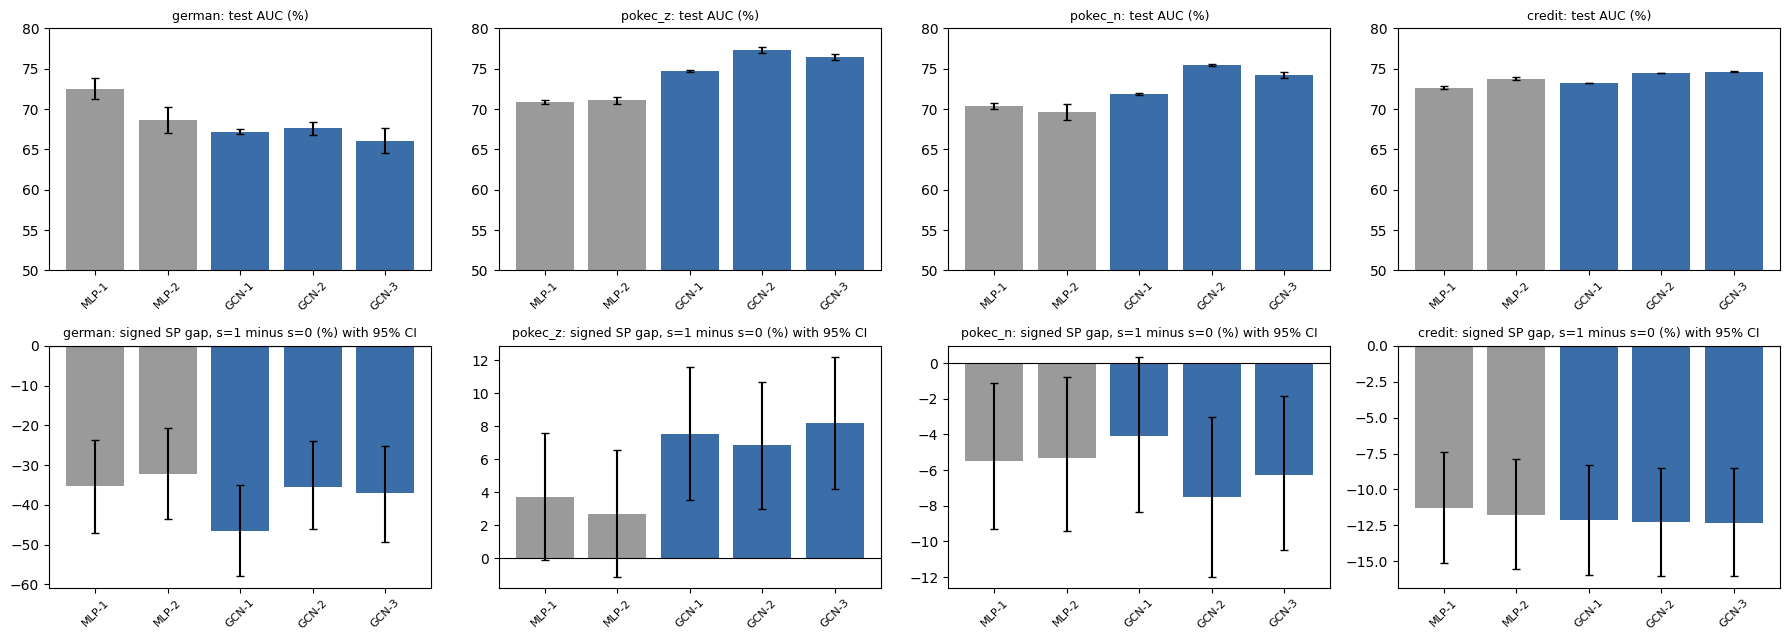

In [7]:
import matplotlib.pyplot as plt
res = pd.read_csv(OUT)
res['config'] = res.model + '-' + res.K.astype(str)
def label_gap(d):
    X, y, s, A, tr, va, te, _ = data[d]
    return y[te][s[te] == 1].mean() - y[te][s[te] == 0].mean()

res['excess_sp_tuned'] = res.sp_signed_tuned - res.dataset.map({d: label_gap(d) for d in DATASETS})
order = [f'{m}-{k}' for m, k in CONFIGS]
cols = ['auc', 'acc_tuned', 'balacc_tuned', 'pos_rate_tuned', 'sp_signed_tuned', 'excess_sp_tuned', 'eo_signed_tuned', 'score_sens_auc']
g = res.groupby(['dataset', 'config'])
mean, std = g[cols].mean() * 100, g[cols].std() * 100
ci = g[['sp_lo_tuned', 'sp_hi_tuned']].mean() * 100          # avg bootstrap CI of signed dSP (tuned threshold)
table = (mean.round(1).astype(str) + ' ± ' + std.round(1).astype(str))
table['sp_tuned_95CI'] = '[' + ci.sp_lo_tuned.round(1).astype(str) + ', ' + ci.sp_hi_tuned.round(1).astype(str) + ']'
table = table.reindex(pd.MultiIndex.from_product([DATASETS, order]))
table.to_csv(f'{RESULTS_DIR}/m3_summary_v4.csv')
print(table.to_string())

fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.5 * len(DATASETS), 6.5), squeeze=False)
colors = ['#9a9a9a' if c.startswith('MLP') else '#3b6ea8' for c in order]
for j, d in enumerate(DATASETS):
    m_ = mean.loc[d].reindex(order); s_ = std.loc[d].reindex(order); c_ = ci.loc[d].reindex(order)
    axes[0, j].bar(order, m_['auc'], yerr=s_['auc'], capsize=3, color=colors)
    axes[0, j].set_ylim(50, 80); axes[0, j].set_title(f'{d}: test AUC (%)', fontsize=9)
    err = np.vstack([m_['sp_signed_tuned'] - c_.sp_lo_tuned, c_.sp_hi_tuned - m_['sp_signed_tuned']])
    axes[1, j].bar(order, m_['sp_signed_tuned'], yerr=err, capsize=3, color=colors)
    axes[1, j].axhline(0, color='k', lw=0.8)
    axes[1, j].set_title(f'{d}: signed SP gap, s=1 minus s=0 (%) with 95% CI', fontsize=9)
    for a in axes[:, j]: a.tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/m3_mlp_vs_gcn_v4.png', dpi=200); plt.show()

Cell 7 - Paired significance tests

In [8]:
def paired_sp_diff(d, cfg_a, cfg_b, seeds=range(5), n_boot=1000):
    """Paired bootstrap on the SAME test nodes: signed SP gap of cfg_b minus that of cfg_a, pooled over seeds."""
    X, y, s, A, tr, va, te, _ = data[d]
    yt, st = y[te], s[te]
    def preds(cfg, sd):
        p = np.load(f'{RESULTS_DIR}/probs/{d}_{cfg}_s{sd}.npy')
        return (p[te] >= pick_threshold(p[va], y[va])).astype(int)
    rng, diffs = np.random.RandomState(0), []
    for sd in seeds:
        ya, yb = preds(cfg_a, sd), preds(cfg_b, sd)
        for _ in range(n_boot // len(seeds)):
            b = rng.randint(0, len(te), len(te))
            diffs.append(group_gaps(yt[b], yb[b], st[b])[0] - group_gaps(yt[b], ya[b], st[b])[0])
    diffs = np.array(diffs) * 100
    return diffs.mean(), *np.percentile(diffs, [2.5, 97.5])

rows = []
for d in DATASETS:
    for a, b in [('MLP2', 'GCN1'), ('MLP2', 'GCN2'), ('MLP2', 'GCN3'), ('GCN1', 'GCN3'), ('GCN2', 'GCN3')]:
        m, lo, hi = paired_sp_diff(d, a, b)
        rows.append(dict(dataset=d, comparison=f'{b} - {a}', diff_signed_SP=round(m, 1),
                         ci95=f'[{lo:+.1f}, {hi:+.1f}]', significant='yes' if (lo > 0 or hi < 0) else 'no',
                         test_label_gap=round(100 * label_gap(d), 1)))
paired = pd.DataFrame(rows)
paired.to_csv(f'{RESULTS_DIR}/m3_paired_tests_v4.csv', index=False)
print(paired.to_string(index=False))

dataset  comparison  diff_signed_SP           ci95 significant  test_label_gap
 german GCN1 - MLP2           -14.3  [-31.2, +3.0]          no           -16.7
 german GCN2 - MLP2            -3.3 [-19.6, +14.0]          no           -16.7
 german GCN3 - MLP2            -4.7 [-22.5, +15.0]          no           -16.7
 german GCN3 - GCN1             9.6  [-5.6, +25.8]          no           -16.7
 german GCN3 - GCN2            -1.5 [-13.4, +10.4]          no           -16.7
pokec_z GCN1 - MLP2             4.9   [-1.7, +9.7]          no             4.5
pokec_z GCN2 - MLP2             4.2  [-1.3, +10.4]          no             4.5
pokec_z GCN3 - MLP2             5.6   [+1.1, +9.8]         yes             4.5
pokec_z GCN3 - GCN1             0.7   [-3.8, +6.4]          no             4.5
pokec_z GCN3 - GCN2             1.4   [-3.3, +5.2]          no             4.5
pokec_n GCN1 - MLP2             1.3   [-3.5, +6.1]          no             0.8
pokec_n GCN2 - MLP2            -2.2   [-7.1, +2.4]  

Cell 8

In [9]:
from sklearn.metrics import balanced_accuracy_score

def acc_threshold(prob_val, y_val):
    """The OLD rule, kept only for this comparison: threshold maximising validation accuracy."""
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([((prob_val >= t) == y_val).mean() for t in grid])]

def label_gap(d):
    X, y, s, A, tr, va, te, _ = data[d]
    return y[te][s[te] == 1].mean() - y[te][s[te] == 0].mean()

def youden_threshold(prob_val, y_val):
    """Fairness-blind: threshold maximising VALIDATION balanced accuracy (= TPR + TNR - 1, Youden's J).
    Unlike plain accuracy, it does not collapse to 'predict the majority class' on imbalanced data."""
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([balanced_accuracy_score(y_val, (prob_val >= t).astype(int)) for t in grid])]

rows = []
for d in DATASETS:
    X, y, s, A, tr, va, te, _ = data[d]
    yt, st = y[te], s[te]
    gap, majority = label_gap(d), max(yt.mean(), 1 - yt.mean())
    for m, K in CONFIGS:
        for sd in SEEDS:
            p = np.load(f'{RESULTS_DIR}/probs/{d}_{m}{K}_s{sd}.npy')
            row = dict(dataset=d, config=f'{m}-{K}', seed=sd, majority_acc=majority,
                       score_auc_s_signed=roc_auc_score(st, p[te]))     # >0.5: scores higher for s=1; <0.5: for s=0
            for tag, thr in [('acc', acc_threshold(p[va], y[va])), ('bal', youden_threshold(p[va], y[va]))]:
                yh = (p[te] >= thr).astype(int)
                sp_, eo, fpr = group_gaps(yt, yh, st)
                row.update({f'thr_{tag}': thr, f'acc_{tag}': accuracy_score(yt, yh),
                            f'balacc_{tag}': balanced_accuracy_score(yt, yh), f'pos_rate_{tag}': yh.mean(),
                            f'sp_{tag}': sp_, f'excess_sp_{tag}': sp_ - gap, f'eo_{tag}': eo, f'fpr_gap_{tag}': fpr})
            rows.append(row)

post = pd.DataFrame(rows)
post.to_csv(f'{RESULTS_DIR}/m3_posthoc_thresholds_v4.csv', index=False)
show = ['majority_acc', 'acc_acc', 'balacc_acc', 'pos_rate_acc', 'excess_sp_acc', 'eo_acc',
        'balacc_bal', 'pos_rate_bal', 'excess_sp_bal', 'eo_bal', 'score_auc_s_signed']
gp = post.groupby(['dataset', 'config'])[show]
summary = (gp.mean() * 100).round(1).astype(str) + ' ± ' + (gp.std() * 100).round(1).astype(str)
summary = summary.reindex(pd.MultiIndex.from_product([DATASETS, [f'{m}-{k}' for m, k in CONFIGS]]))
summary.to_csv(f'{RESULTS_DIR}/m3_posthoc_summary_v4.csv')
pd.set_option('display.width', 300)
print(summary.to_string())

              majority_acc     acc_acc  balacc_acc pos_rate_acc excess_sp_acc        eo_acc  balacc_bal pos_rate_bal excess_sp_bal       eo_bal score_auc_s_signed
german  MLP-1   70.0 ± 0.0  71.6 ± 0.6  56.6 ± 1.3   90.1 ± 2.1    -1.2 ± 3.7   -12.8 ± 3.2  66.5 ± 2.5  58.3 ± 13.8   -18.4 ± 2.3  -23.7 ± 6.7         24.1 ± 1.6
        MLP-2   70.0 ± 0.0  69.8 ± 1.6  58.3 ± 1.7   82.0 ± 5.5    -1.2 ± 6.7   -16.0 ± 5.7  62.5 ± 2.8   63.0 ± 7.7   -15.4 ± 5.0  -27.5 ± 5.4         28.7 ± 2.6
        GCN-1   70.0 ± 0.0  70.2 ± 1.5  55.1 ± 0.9   89.8 ± 5.4   -3.4 ± 10.5  -14.1 ± 10.8  61.3 ± 1.5   67.5 ± 5.5   -29.8 ± 5.1  -42.5 ± 6.1         18.0 ± 1.5
        GCN-2   70.0 ± 0.0  69.0 ± 1.1  55.1 ± 0.7   86.6 ± 1.5    -1.4 ± 1.8   -13.8 ± 2.1  63.5 ± 1.4   47.2 ± 7.0   -18.7 ± 2.1  -27.8 ± 2.8         27.4 ± 1.2
        GCN-3   70.0 ± 0.0  68.7 ± 2.7  55.1 ± 3.4   86.1 ± 3.7    -1.6 ± 7.5   -14.0 ± 6.4  61.9 ± 1.2   58.8 ± 5.8   -20.2 ± 3.4  -36.6 ± 1.8         25.4 ± 2.3
pokec_z MLP-1   53.6 ±

Cell 9 - Shared building blocks. This cell provides:

* **Graph plumbing**: edge lists, edge dropout, and GCN normalisation rebuilt after dropping edges.  
* `GraphConv`: one GCN layer, identical in form to the DGL and PyG layers the authors used.  
* `features_with_sens`: NIFTY needs s as a raw 0/1 column it can flip, so this cell builds that feature matrix.  
* `sens_train_idx`: the nodes whose sensitive attribute FairGNN may see.
NIFTY’s two stability metrics.  
* `finalize`: scores a trained model under both selection rules and writes results to disk.

In [10]:
import copy
import torch.nn as nn
from torch.nn.utils.parametrizations import spectral_norm

M4_OUT = f'{RESULTS_DIR}/m4_results.csv'
os.makedirs(f'{RESULTS_DIR}/probs', exist_ok=True)

# ---------- graph plumbing ----------
EDGE_INDEX = {}
def edge_index_of(d):
    """Directed edge list [2, E] (both directions of every undirected edge, no self-loops)."""
    if d not in EDGE_INDEX:
        A = data[d][3].tocoo()
        EDGE_INDEX[d] = torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long, device=device)
    return EDGE_INDEX[d]

def drop_edge(ei, p):
    """Remove each directed edge independently with probability p (= torch_geometric.utils.dropout_adj)."""
    if p <= 0:
        return ei
    return ei[:, torch.rand(ei.size(1), device=ei.device) >= p]

def sym_norm_adj(ei, n):
    """D^-1/2 (A+I) D^-1/2 from an edge list, exactly as PyG's GCNConv normalises (degree counted on target)."""
    loops = torch.arange(n, device=ei.device)
    row, col = torch.cat([ei[0], loops]), torch.cat([ei[1], loops])
    deg = torch.zeros(n, device=ei.device).scatter_add_(0, col, torch.ones(col.numel(), device=ei.device))
    dinv = deg.pow(-0.5)
    return torch.sparse_coo_tensor(torch.stack([col, row]), dinv[row] * dinv[col], (n, n)).coalesce()

class GraphConv(nn.Module):
    """One GCN layer as in DGL/PyG: H' = A_hat (H W) + b  (Glorot-initialised W, zero bias)."""
    def __init__(self, i, o):
        super().__init__()
        self.lin = nn.Linear(i, o, bias=False)
        nn.init.xavier_uniform_(self.lin.weight)
        self.bias = nn.Parameter(torch.zeros(o))
    def forward(self, x, A):
        return torch.sparse.mm(A, self.lin(x)) + self.bias

# ---------- data the baselines need beyond M3 ----------
SENS_FEATURES = {}
def features_with_sens(d):
    """Same features as M3 but WITH the sensitive attribute as a raw 0/1 column.
    NIFTY needs it: its augmentation flips that column (x -> 1 - x), so it must not be rescaled to [-1, 1]."""
    if d not in SENS_FEATURES:
        Xs, _, s_, _, _, _, _, cols_ = load_dataset(d, sens_in_features=True)
        j = cols_.index(CFG[d]['sens'])
        Xs[:, j] = s_
        SENS_FEATURES[d] = (Xs, j)
    return SENS_FEATURES[d]

# FairGNN assumes only a few nodes have a KNOWN sensitive attribute. Counts follow the authors' scripts:
# Pokec 200 (FairGNN paper, Table 1); German 100 / Credit 6000 (NIFTY's FairGNN baseline script).
SENS_NUMBER = {'pokec_z': 200, 'pokec_n': 200, 'german': 100, 'credit': 6000}
def sens_train_idx(d):
    """Nodes whose sensitive attribute FairGNN may see: drawn from nodes outside val/test (authors' load_pokec)."""
    X, y, s, A, tr, va, te, _ = data[d]
    pool = list(set(np.where(s >= 0)[0]) - set(va) - set(te))
    random.seed(20); random.shuffle(pool)
    return np.array(pool[:SENS_NUMBER[d]])

# ---------- NIFTY's two extra metrics ----------
def stability_metrics(predict, x, sens_col, te, thresholds, seed):
    """On test nodes:
    cf_*     counterfactual unfairness: share of predictions that change when ONLY the sensitive column is flipped
             (only defined when the sensitive attribute is an input feature; NaN otherwise)
    instab_* instability: share of predictions that change when N(0,1) noise is added to every feature."""
    p = predict(x)
    g = torch.Generator().manual_seed(seed)
    p_noise = predict(x + torch.randn(tuple(x.shape), generator=g).to(x.device))
    p_cf = None
    if sens_col is not None:
        xc = x.clone(); xc[:, sens_col] = 1 - xc[:, sens_col]
        p_cf = predict(xc)
    out = {}
    for tag, thr in thresholds.items():
        yh = p[te] >= thr
        out[f'instab_{tag}'] = float(((p_noise[te] >= thr) != yh).mean())
        out[f'cf_{tag}'] = float(((p_cf[te] >= thr) != yh).mean()) if p_cf is not None else np.nan
    return out

def snapshot(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()}

def finalize(d, method, seed, model, snaps, predict, x, sens_col, epochs_run, est_acc=np.nan, record=True):
    """Evaluate the model under BOTH model-selection rules and (optionally) save results + probabilities.
    'ours'  = epoch with best validation AUC (fairness-blind; same rule as M3)
    'paper' = the selection rule in the method's own released code (falls back to 'ours' if never satisfied)"""
    X, y, s, A, tr, va, te, _ = data[d]
    rows = []
    for sel in ['ours', 'paper']:
        met = snaps[sel]['state'] is not None
        snap = snaps[sel] if met else snaps['ours']
        model.load_state_dict(snap['state']); model.eval()
        prob = predict(x)
        r = evaluate(prob, y, s, va, te)
        r.update(stability_metrics(predict, x, sens_col, te, {'05': 0.5, 'tuned': r['thr_tuned']}, seed))
        r.update(dataset=d, method=method, selection=sel, seed=seed, best_epoch=snap['epoch'],
                 epochs_run=epochs_run, paper_rule_met=met, est_acc=est_acc)
        rows.append(r)
        if record:
            np.save(f'{RESULTS_DIR}/probs/{d}_{method}-{sel}_s{seed}.npy', prob.astype(np.float32))
    if record:   # both rows written together, so an interrupted run never leaves half a result
        df = pd.DataFrame(rows); df = df[sorted(df.columns)]
        df.to_csv(M4_OUT, mode='a', header=not os.path.exists(M4_OUT), index=False)
    return rows

def make_predict(forward):
    def predict(x_):
        with torch.no_grad():
            return torch.sigmoid(forward(x_)).cpu().numpy()
    return predict

print('M4 building blocks ready')

M4 building blocks ready


Cell 10 - Baseline 1, FairGNN.

* Hyperparameters are copied from the authors’ shell scripts for Pokec and from NIFTY’s FairGNN script for German/Credit (the FairGNN paper doesn’t cover those datasets).  
* `pretrain_estimator` reproduces `train_sens.py`.  
* Each training epoch follows the two steps of the authors’ `optimize()` exactly.  
* Calling it with `alpha=0, beta=0` gives “GCN-FG”: the same network with every fairness term off.

In [11]:
FAIRGNN_HP = {
    # Authors' scripts: FairGNN/src/scripts/pokec_{z,n}/train_fairGCN.sh
    'pokec_z': dict(alpha=100, beta=1,    hidden=128, est_hidden=128, epochs=2000, acc_thr=0.69, roc_thr=0.76),
    'pokec_n': dict(alpha=50,  beta=1,    hidden=128, est_hidden=128, epochs=1800, acc_thr=0.68, roc_thr=0.73),
    # The FairGNN paper has no German/Credit results; these follow NIFTY's FairGNN baseline (README command)
    'german':  dict(alpha=4,   beta=0.01, hidden=32,  est_hidden=16,  epochs=1000, acc_thr=None, roc_thr=None),
    'credit':  dict(alpha=4,   beta=0.01, hidden=32,  est_hidden=16,  epochs=1000, acc_thr=None, roc_thr=None),
}
FG_COMMON = dict(lr=1e-3, wd=1e-5, dropout=0.5)

class GCNBody(nn.Module):
    """FairGNN's GCN_Body: GCN -> ReLU -> dropout -> GCN (2 layers of message passing)."""
    def __init__(self, i, h, dropout):
        super().__init__()
        self.gc1, self.gc2, self.drop = GraphConv(i, h), GraphConv(h, h), nn.Dropout(dropout)
    def forward(self, x, A):
        return self.gc2(self.drop(Fnn.relu(self.gc1(x, A))), A)

class GCNHead(nn.Module):
    """FairGNN's GCN = GCN_Body + linear output. Used as the sensitive-attribute estimator f_E."""
    def __init__(self, i, h, dropout):
        super().__init__()
        self.body, self.fc = GCNBody(i, h, dropout), nn.Linear(h, 1)
    def forward(self, x, A):
        return self.fc(self.body(x, A)).squeeze(-1)

class FairGNNModel(nn.Module):
    """f_E estimator (guesses s), f_G GNN encoder, f_C classifier head (predicts y), f_A adversary (guesses s from h)."""
    def __init__(self, i, hp):
        super().__init__()
        self.estimator = GCNHead(i, hp['est_hidden'], FG_COMMON['dropout'])
        self.GNN = GCNBody(i, hp['hidden'], FG_COMMON['dropout'])
        self.classifier = nn.Linear(hp['hidden'], 1)
        self.adv = nn.Linear(hp['hidden'], 1)
    def forward(self, x, A):
        return self.classifier(self.GNN(x, A)).squeeze(-1)

EST_CACHE = {}
def pretrain_estimator(d, hp):
    """FairGNN step 0 (authors' train_sens.py): train f_E to predict s from the few nodes whose s is known.
    Seed 41, 800 epochs, checkpoint = best sensitive-attribute accuracy on VALIDATION nodes (as in their code)."""
    key = (d, hp['est_hidden'])
    if key in EST_CACHE:
        return EST_CACHE[key]
    X, y, s, A, tr, va, te, _ = data[d]
    torch.manual_seed(41); np.random.seed(41)
    x, A_hat = torch.tensor(X, device=device), TORCH_ADJ[d]
    st = torch.tensor(s, dtype=torch.float32, device=device)
    idx_s = torch.tensor(sens_train_idx(d), dtype=torch.long, device=device)
    est = GCNHead(X.shape[1], hp['est_hidden'], FG_COMMON['dropout']).to(device)
    opt = torch.optim.Adam(est.parameters(), lr=FG_COMMON['lr'], weight_decay=FG_COMMON['wd'])
    best_acc, best_state, best_test = -1.0, None, np.nan
    for ep in range(801):
        est.train(); opt.zero_grad()
        Fnn.binary_cross_entropy_with_logits(est(x, A_hat)[idx_s], st[idx_s]).backward()
        opt.step()
        if ep % 10 == 0:
            est.eval()
            with torch.no_grad():
                pred = (est(x, A_hat) > 0).float().cpu().numpy()
            acc_val, acc_test = (pred[va] == s[va]).mean(), (pred[te] == s[te]).mean()
            if acc_val > best_acc:
                best_acc, best_state, best_test = acc_val, snapshot(est), acc_test
    EST_CACHE[key] = (best_state, best_test)
    print(f'  [{d}] estimator f_E: test accuracy at guessing s = {best_test:.3f} (from {len(idx_s)} known labels)')
    return EST_CACHE[key]

def train_fairgnn(d, seed, alpha=None, beta=None, method='FairGNN', epochs=None, record=True):
    """alpha=beta=0 turns every fairness term off -> the same architecture as a plain GCN ('GCN-FG')."""
    hp = dict(FAIRGNN_HP[d])
    if alpha is not None: hp['alpha'] = alpha
    if beta is not None: hp['beta'] = beta
    if epochs is not None: hp['epochs'] = epochs
    X, y, s, A, tr, va, te, _ = data[d]
    est_state, est_acc = pretrain_estimator(d, hp)

    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    x, A_hat = torch.tensor(X, device=device), TORCH_ADJ[d]
    yt = torch.tensor(y, dtype=torch.float32, device=device)
    st = torch.tensor(s, dtype=torch.float32, device=device)
    tr_t = torch.tensor(tr, dtype=torch.long, device=device)
    idx_s = torch.tensor(sens_train_idx(d), dtype=torch.long, device=device)

    model = FairGNNModel(X.shape[1], hp).to(device)
    model.estimator.load_state_dict(est_state)
    # As in the authors' code the estimator sits in optimizer_G, but its output is detached, so it never changes.
    opt_G = torch.optim.Adam(list(model.GNN.parameters()) + list(model.classifier.parameters())
                             + list(model.estimator.parameters()), lr=FG_COMMON['lr'], weight_decay=FG_COMMON['wd'])
    opt_A = torch.optim.Adam(model.adv.parameters(), lr=FG_COMMON['lr'], weight_decay=FG_COMMON['wd'])
    bce = nn.BCEWithLogitsLoss()
    snaps = {'ours': dict(score=-np.inf, state=None, epoch=-1), 'paper': dict(score=np.inf, state=None, epoch=-1)}

    for ep in range(hp['epochs']):
        model.train()
        # --- step 1: update encoder f_G + classifier f_C (adversary frozen) ---
        model.adv.requires_grad_(False); opt_G.zero_grad()
        s_score = torch.sigmoid(model.estimator(x, A_hat).detach())   # f_E's guess of s for EVERY node...
        s_score[idx_s] = st[idx_s]                                     # ...replaced by the truth where it is known
        h = model.GNN(x, A_hat)
        y_logit = model.classifier(h).squeeze(-1)
        y_score = torch.sigmoid(y_logit)
        cov = torch.abs(torch.mean((s_score - s_score.mean()) * (y_score - y_score.mean())))  # |Cov(s, y_hat)|
        cls_loss = bce(y_logit[tr_t], yt[tr_t])
        adv_loss = bce(model.adv(h).squeeze(-1), s_score)               # how well f_A recovers s from h
        (cls_loss + hp['alpha'] * cov - hp['beta'] * adv_loss).backward()   # minus: f_G tries to FOOL f_A
        opt_G.step()
        # --- step 2: update adversary f_A on the (detached) representation ---
        model.adv.requires_grad_(True); opt_A.zero_grad()
        bce(model.adv(h.detach()).squeeze(-1), s_score).backward()
        opt_A.step()

        # --- model selection, evaluated every epoch ---
        model.eval()
        with torch.no_grad():
            prob = torch.sigmoid(model(x, A_hat)).cpu().numpy()
        val_auc = roc_auc_score(y[va], prob[va])
        if val_auc > snaps['ours']['score']:
            snaps['ours'].update(score=val_auc, state=snapshot(model), epoch=ep)
        if hp['acc_thr'] is None:            # German/Credit: NIFTY's FairGNN script keeps the best validation AUC
            ok, paper_score = True, -val_auc
        else:                                # Pokec: FairGNN's own rule = fairest validation epoch above acc/AUC floors
            yh = (prob[va] > 0.5).astype(int)
            g = group_gaps(y[va], yh, s[va])
            ok = (yh == y[va]).mean() > hp['acc_thr'] and val_auc > hp['roc_thr']
            paper_score = abs(g[0]) + abs(g[1])
        if ok and paper_score < snaps['paper']['score']:
            snaps['paper'].update(score=paper_score, state=snapshot(model), epoch=ep)

    predict = make_predict(lambda x_: model(x_, A_hat))
    return finalize(d, method, seed, model, snaps, predict, x, None, hp['epochs'], est_acc, record)

print('FairGNN ready')

FairGNN ready


Cell 11 - Baseline 2, NIFTY, plus its vanilla GCN (“GCN-NF”).  

Settings are the authors’ README command, which matches the paper’s Section 5: λ = 0.6, edge drop 0.001, feature drop 0.1, hidden size 16, 1000 epochs. Two quirks of the authors’ code are reproduced on purpose and commented in the code:

* **Shared noise draw**: the feature augmentation adds a single shared random number to every selected column, not independent noise per column.
* **Gradients carry over**: gradients aren’t reset between the invariance step and the classification step.

In [12]:
NIFTY_HP = dict(hidden=16, proj_hidden=16, lr=1e-3, wd=1e-5, epochs=1000,
                sim_coeff=0.6, drop_edge=0.001, drop_feat=0.1)   # authors' README command = paper Sec. 5 settings

def SNLinear(i, o, bias=True):
    """Linear layer with spectral normalisation (largest singular value of W kept at 1 -> Lipschitz-bounded)."""
    lin = nn.Linear(i, o, bias=bias)
    nn.init.xavier_uniform_(lin.weight)
    if bias: nn.init.zeros_(lin.bias)
    return spectral_norm(lin)

class NiftyEncoder(nn.Module):
    """spectral_norm(GCNConv(nfeat, 16)): one layer of message passing, no activation."""
    def __init__(self, i, h):
        super().__init__()
        self.lin, self.bias = SNLinear(i, h, bias=False), nn.Parameter(torch.zeros(h))
    def forward(self, x, A):
        return torch.sparse.mm(A, self.lin(x)) + self.bias

class NIFTYModel(nn.Module):
    def __init__(self, i, hp):
        super().__init__()
        h, ph = hp['hidden'], hp['proj_hidden']
        self.encoder = NiftyEncoder(i, h)
        self.fc1 = nn.Sequential(SNLinear(h, ph), nn.BatchNorm1d(ph), nn.ReLU())   # projector
        self.fc2 = nn.Sequential(SNLinear(ph, h), nn.BatchNorm1d(h))
        self.fc3 = nn.Sequential(SNLinear(h, h), nn.BatchNorm1d(h), nn.ReLU())     # predictor
        self.fc4 = SNLinear(h, h)
        self.c1 = SNLinear(h, 1)                                                     # classifier
    def forward(self, x, A):     return self.encoder(x, A)
    def projection(self, z):     return self.fc2(self.fc1(z))
    def prediction(self, z):     return self.fc4(self.fc3(z))
    def classifier(self, z):     return self.c1(z).squeeze(-1)

def neg_cos(a, b):
    """Negative cosine similarity with stop-gradient on b (BYOL/SimSiam-style)."""
    return -Fnn.cosine_similarity(a, b.detach(), dim=-1).mean()

def drop_feature(x, p, sens_col, flip):
    """Authors' augmentation: pick each non-sensitive column with prob p and add ONE shared N(0,1) draw to all
    picked columns; optionally flip the sensitive column (the counterfactual view)."""
    mask = torch.rand(x.size(1), device=x.device) < p
    mask[sens_col] = False
    x = x.clone()
    x[:, mask] += torch.randn(1, device=x.device)
    if flip:
        x[:, sens_col] = 1 - x[:, sens_col]
    return x

def train_nifty(d, seed, epochs=None, record=True, method='NIFTY'):
    hp = dict(NIFTY_HP)
    if epochs is not None: hp['epochs'] = epochs
    Xs, sc = features_with_sens(d)
    _, y, s, A, tr, va, te, _ = data[d]
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    x, n = torch.tensor(Xs, device=device), Xs.shape[0]
    ei, A_full = edge_index_of(d), TORCH_ADJ[d]
    yt = torch.tensor(y, dtype=torch.float32, device=device)
    tr_t = torch.tensor(tr, dtype=torch.long, device=device)
    va_t = torch.tensor(va, dtype=torch.long, device=device)
    model = NIFTYModel(x.size(1), hp).to(device)
    enc = list(model.encoder.parameters())
    opt1 = torch.optim.Adam(enc + [p for m in [model.fc1, model.fc2, model.fc3, model.fc4] for p in m.parameters()],
                            lr=hp['lr'], weight_decay=hp['wd'])
    opt2 = torch.optim.Adam(list(model.c1.parameters()) + enc, lr=hp['lr'], weight_decay=hp['wd'])
    bce = nn.BCEWithLogitsLoss()
    def sim(za, zb, idx):
        # projector p, predictor h; each view's prediction must match the OTHER view's projection
        pa, pb = model.projection(za), model.projection(zb)
        ha, hb = model.prediction(pa), model.prediction(pb)
        return hp['sim_coeff'] * (neg_cos(ha[idx], pb[idx]) / 2 + neg_cos(hb[idx], pa[idx]) / 2)

    # fixed augmented views used for the authors' validation loss
    A_v1, A_v2 = sym_norm_adj(drop_edge(ei, hp['drop_edge']), n), sym_norm_adj(drop_edge(ei, hp['drop_edge']), n)
    xv1, xv2 = drop_feature(x, hp['drop_feat'], sc, flip=False), drop_feature(x, hp['drop_feat'], sc, flip=True)
    snaps = {'ours': dict(score=-np.inf, state=None, epoch=-1), 'paper': dict(score=np.inf, state=None, epoch=-1)}

    for ep in range(hp['epochs'] + 1):
        model.train(); opt1.zero_grad(); opt2.zero_grad()
        # two augmented views: view 1 = noisy features + dropped edges; view 2 = same kind of noise + FLIPPED s
        A1, A2 = sym_norm_adj(drop_edge(ei, hp['drop_edge']), n), sym_norm_adj(drop_edge(ei, hp['drop_edge']), n)
        x1, x2 = drop_feature(x, hp['drop_feat'], sc, flip=False), drop_feature(x, hp['drop_feat'], sc, flip=True)
        # (a) invariance loss: representations of the two views must agree (training nodes only)
        sim(model(x1, A1), model(x2, A2), tr_t).backward()
        opt1.step()
        # (b) classification loss on both views. As in the authors' code, gradients are NOT zeroed in between,
        #     so the encoder's update in opt2 also contains the invariance gradient from (a).
        z1, z2 = model(x1, A1), model(x2, A2)
        ((1 - hp['sim_coeff']) * (bce(model.classifier(z1)[tr_t], yt[tr_t]) / 2 +
                                  bce(model.classifier(z2)[tr_t], yt[tr_t]) / 2)).backward()
        opt2.step()

        model.eval()
        with torch.no_grad():
            zv1, zv2 = model(xv1, A_v1), model(xv2, A_v2)
            val_loss = (sim(zv1, zv2, va_t) + bce(model.classifier(zv1)[va_t], yt[va_t]) / 2
                        + bce(model.classifier(zv2)[va_t], yt[va_t]) / 2).item()
            prob = torch.sigmoid(model.classifier(model(x, A_full))).cpu().numpy()
        val_auc = roc_auc_score(y[va], prob[va])
        if val_auc > snaps['ours']['score']:
            snaps['ours'].update(score=val_auc, state=snapshot(model), epoch=ep)
        if val_loss < snaps['paper']['score']:              # authors' rule: lowest validation (invariance + BCE) loss
            snaps['paper'].update(score=val_loss, state=snapshot(model), epoch=ep)

    predict = make_predict(lambda x_: model.classifier(model(x_, A_full)))
    return finalize(d, method, seed, model, snaps, predict, x, sc, hp['epochs'] + 1, record=record)

class NiftyGCN(nn.Module):
    """NIFTY's vanilla 'gcn' baseline: GCNConv(nfeat, 16) -> Linear(16, 1). Same encoder width, no fairness terms."""
    def __init__(self, i, h):
        super().__init__()
        self.gc, self.fc = GraphConv(i, h), nn.Linear(h, 1)
        nn.init.xavier_uniform_(self.fc.weight); nn.init.zeros_(self.fc.bias)
    def forward(self, x, A):
        return self.fc(self.gc(x, A)).squeeze(-1)

def train_nifty_gcn(d, seed, epochs=None, record=True, method='GCN-NF'):
    hp = dict(NIFTY_HP)
    if epochs is not None: hp['epochs'] = epochs
    Xs, sc = features_with_sens(d)
    _, y, s, A, tr, va, te, _ = data[d]
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    x, A_full = torch.tensor(Xs, device=device), TORCH_ADJ[d]
    yt = torch.tensor(y, dtype=torch.float32, device=device)
    tr_t = torch.tensor(tr, dtype=torch.long, device=device)
    model = NiftyGCN(x.size(1), hp['hidden']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    snaps = {'ours': dict(score=-np.inf, state=None, epoch=-1), 'paper': dict(score=np.inf, state=None, epoch=-1)}
    for ep in range(hp['epochs'] + 1):
        model.train(); opt.zero_grad()
        Fnn.binary_cross_entropy_with_logits(model(x, A_full)[tr_t], yt[tr_t]).backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            logit = model(x, A_full)
            val_loss = Fnn.binary_cross_entropy_with_logits(logit[va], yt[va]).item()
            prob = torch.sigmoid(logit).cpu().numpy()
        val_auc = roc_auc_score(y[va], prob[va])
        if val_auc > snaps['ours']['score']:
            snaps['ours'].update(score=val_auc, state=snapshot(model), epoch=ep)
        if val_loss < snaps['paper']['score']:              # authors' rule: lowest validation BCE
            snaps['paper'].update(score=val_loss, state=snapshot(model), epoch=ep)
    predict = make_predict(lambda x_: model(x_, A_full))
    return finalize(d, method, seed, model, snaps, predict, x, sc, hp['epochs'] + 1, record=record)

print('NIFTY ready')

NIFTY ready


Cell 12 - smoke test (~1 min).  

It runs all four methods on German for 30 epochs and saves nothing. (Debugging step)

In [13]:
for name, fn in [('GCN-FG',  lambda: train_fairgnn('german', 0, alpha=0, beta=0, epochs=30, record=False)),
                 ('FairGNN', lambda: train_fairgnn('german', 0, epochs=30, record=False)),
                 ('GCN-NF',  lambda: train_nifty_gcn('german', 0, epochs=30, record=False)),
                 ('NIFTY',   lambda: train_nifty('german', 0, epochs=30, record=False))]:
    t = time.time()
    rows = fn()
    for r in rows:
        assert np.isfinite(r['auc']) and 0 <= r['dsp_tuned'] <= 1, f'{name}: bad metrics {r}'
    o = rows[0]
    print(f"{name:8s} OK  AUC={o['auc']:.3f} SP(s1-s0)={100*o['sp_signed_tuned']:+.1f} "
          f"CF={o['cf_05']:.3f} instab={o['instab_05']:.3f}  ({time.time()-t:.1f}s)")
print('Smoke test passed: all four methods train and evaluate.')

  [german] estimator f_E: test accuracy at guessing s = 0.912 (from 100 known labels)
GCN-FG   OK  AUC=0.631 SP(s1-s0)=-18.9 CF=nan instab=0.092  (3.5s)
FairGNN  OK  AUC=0.632 SP(s1-s0)=+0.2 CF=nan instab=0.128  (0.6s)
GCN-NF   OK  AUC=0.615 SP(s1-s0)=-26.7 CF=0.084 instab=0.092  (0.5s)
NIFTY    OK  AUC=0.450 SP(s1-s0)=+2.3 CF=0.136 instab=0.116  (1.5s)
Smoke test passed: all four methods train and evaluate.


Cell 13 - the full run.  

That’s 4 methods × 4 datasets × 5 seeds = 80 runs. My rough estimate is 1–1.5 hours on a T4; FairGNN on Pokec is the slow part at 2,000 epochs. Each run is saved as soon as it finishes, so after a disconnect, re-run Cells 0–2, 4, 5 and 9–11, then this cell, and it skips completed runs. Cell 5 will also skip everything already done.

In [14]:
M4_METHODS = {
    'GCN-FG':  lambda d, sd: train_fairgnn(d, sd, alpha=0, beta=0, method='GCN-FG'),
    'FairGNN': lambda d, sd: train_fairgnn(d, sd),
    'GCN-NF':  lambda d, sd: train_nifty_gcn(d, sd),
    'NIFTY':   lambda d, sd: train_nifty(d, sd),
}
M4_DATASETS = ['german', 'credit', 'pokec_z', 'pokec_n']     # fast datasets first
M4_SEEDS = [0, 1, 2, 3, 4]

done = set()
if os.path.exists(M4_OUT):
    prev = pd.read_csv(M4_OUT)
    done = set(zip(prev.dataset, prev.method, prev.seed))

for d in M4_DATASETS:
    for method, fn in M4_METHODS.items():
        for sd in M4_SEEDS:
            if (d, method, sd) in done:
                continue
            t = time.time()
            ours, paper = fn(d, sd)
            print(f"{d:8s} {method:8s} seed {sd}: [ours] AUC={ours['auc']:.3f} balacc={ours['balacc_tuned']:.3f} "
                  f"SP(s1-s0)={100*ours['sp_signed_tuned']:+.1f} | [paper] AUC={paper['auc']:.3f} "
                  f"dSP@0.5={100*paper['dsp_05']:.1f} rule_met={paper['paper_rule_met']}  ({time.time()-t:.0f}s)")

german   GCN-FG   seed 0: [ours] AUC=0.666 balacc=0.634 SP(s1-s0)=-40.1 | [paper] AUC=0.666 dSP@0.5=40.9 rule_met=True  (9s)
german   GCN-FG   seed 1: [ours] AUC=0.668 balacc=0.626 SP(s1-s0)=-43.7 | [paper] AUC=0.668 dSP@0.5=40.9 rule_met=True  (9s)
german   GCN-FG   seed 2: [ours] AUC=0.677 balacc=0.649 SP(s1-s0)=-41.1 | [paper] AUC=0.677 dSP@0.5=39.0 rule_met=True  (9s)
german   GCN-FG   seed 3: [ours] AUC=0.668 balacc=0.633 SP(s1-s0)=-40.3 | [paper] AUC=0.668 dSP@0.5=38.8 rule_met=True  (9s)
german   GCN-FG   seed 4: [ours] AUC=0.676 balacc=0.590 SP(s1-s0)=-30.0 | [paper] AUC=0.676 dSP@0.5=46.7 rule_met=True  (9s)
german   FairGNN  seed 0: [ours] AUC=0.634 balacc=0.574 SP(s1-s0)=-0.2 | [paper] AUC=0.634 dSP@0.5=0.2 rule_met=True  (9s)
german   FairGNN  seed 1: [ours] AUC=0.637 balacc=0.633 SP(s1-s0)=-5.8 | [paper] AUC=0.637 dSP@0.5=6.4 rule_met=True  (9s)
german   FairGNN  seed 2: [ours] AUC=0.635 balacc=0.600 SP(s1-s0)=+1.2 | [paper] AUC=0.635 dSP@0.5=6.8 rule_met=True  (9s)
german

Cell 14 - reproduction check.  

This is the “can you duplicate the results” table the PDF asks for. It uses each paper’s own protocol and compares against the published means. The rule_met column shows in how many seeds FairGNN’s fairness-based selection rule was ever satisfied; when it wasn’t, that seed falls back to best-AUC selection. That matters when interpreting any gap from the paper.

In [15]:
# Published means (%). Sources: FairGNN paper Table 3; NIFTY paper Table 2 (GCN, NIFTY-GCN) and Table 1 (FairGCN).
PAPER = {
    ('pokec_z', 'GCN-FG'):  dict(src='FairGNN T3 GCN',     acc=70.2, auc=77.2, dsp=9.9,  deo=9.1),
    ('pokec_z', 'FairGNN'): dict(src='FairGNN T3 FairGCN', acc=70.0, auc=76.7, dsp=0.9,  deo=1.7),
    ('pokec_n', 'GCN-FG'):  dict(src='FairGNN T3 GCN',     acc=70.5, auc=75.1, dsp=9.6,  deo=12.8),
    ('pokec_n', 'FairGNN'): dict(src='FairGNN T3 FairGCN', acc=70.1, auc=74.9, dsp=0.8,  deo=1.1),
    ('german',  'GCN-NF'):  dict(src='NIFTY T2 GCN',       auc=74.00, f1=80.05, dsp=41.94, deo=31.11, cf=21.36, instab=11.84),
    ('german',  'NIFTY'):   dict(src='NIFTY T2 NIFTY-GCN', auc=70.32, f1=81.98, dsp=15.08, deo=12.56, cf=1.12,  instab=4.48),
    ('german',  'FairGNN'): dict(src='NIFTY T1 FairGCN',   auc=75.21, f1=81.52, dsp=38.12, deo=26.70, instab=7.84),
    ('credit',  'GCN-NF'):  dict(src='NIFTY T2 GCN',       auc=72.97, f1=82.02, dsp=10.76, deo=8.71,  cf=2.04,  instab=5.63),
    ('credit',  'NIFTY'):   dict(src='NIFTY T2 NIFTY-GCN', auc=71.92, f1=81.99, dsp=12.40, deo=10.09, cf=0.63,  instab=0.95),
    ('credit',  'FairGNN'): dict(src='NIFTY T1 FairGCN',   auc=72.69, f1=80.16, dsp=15.86, deo=14.43, instab=5.73),
}
OURS_COL = dict(acc='acc_05', auc='auc', f1='f1_05', dsp='dsp_05', deo='deo_05', cf='cf_05', instab='instab_05')

m4 = pd.read_csv(M4_OUT)
pp = m4[m4.selection == 'paper']
rows = []
for (d, meth), ref in PAPER.items():
    sub = pp[(pp.dataset == d) & (pp.method == meth)]
    if sub.empty:
        continue
    for k, v in ref.items():
        if k == 'src':
            continue
        vals = 100 * sub[OURS_COL[k]]
        rows.append(dict(dataset=d, method=meth, source=ref['src'], metric=k, paper=v,
                         ours=f'{vals.mean():.1f} ± {vals.std():.1f}', diff=round(vals.mean() - v, 1),
                         rule_met=f"{int(sub.paper_rule_met.sum())}/{len(sub)}"))
repro = pd.DataFrame(rows)
repro.to_csv(f'{RESULTS_DIR}/m4_reproduction.csv', index=False)
pd.set_option('display.width', 250)
print(repro.to_string(index=False))

dataset  method             source metric  paper        ours  diff rule_met
pokec_z  GCN-FG     FairGNN T3 GCN    acc  70.20  69.5 ± 1.0  -0.7      5/5
pokec_z  GCN-FG     FairGNN T3 GCN    auc  77.20  76.0 ± 0.4  -1.2      5/5
pokec_z  GCN-FG     FairGNN T3 GCN    dsp   9.90   7.4 ± 1.4  -2.5      5/5
pokec_z  GCN-FG     FairGNN T3 GCN    deo   9.10   6.9 ± 1.2  -2.2      5/5
pokec_z FairGNN FairGNN T3 FairGCN    acc  70.00  68.6 ± 0.4  -1.4      0/5
pokec_z FairGNN FairGNN T3 FairGCN    auc  76.70  74.6 ± 0.3  -2.1      0/5
pokec_z FairGNN FairGNN T3 FairGCN    dsp   0.90   2.5 ± 1.5   1.6      0/5
pokec_z FairGNN FairGNN T3 FairGCN    deo   1.70   2.1 ± 1.0   0.4      0/5
pokec_n  GCN-FG     FairGNN T3 GCN    acc  70.50  70.0 ± 0.2  -0.5      5/5
pokec_n  GCN-FG     FairGNN T3 GCN    auc  75.10  73.9 ± 0.2  -1.2      5/5
pokec_n  GCN-FG     FairGNN T3 GCN    dsp   9.60   7.4 ± 1.5  -2.2      5/5
pokec_n  GCN-FG     FairGNN T3 GCN    deo  12.80  10.5 ± 1.8  -2.3      5/5
pokec_n Fair

Cell 15 - the main comparison under our protocol.  

It produces three things, all report material:

* **The main results table**: all six models side by side (MLP-2 and GCN-2 from M3, plus the four M4 runs).
* **Paired bootstrap tests**: does each fairness method actually reduce |ΔSP| and |ΔEO| compared with its own vanilla GCN, and at what AUC cost?
* **A fairness–accuracy trade-off figure**: one panel per dataset.

                           auc balacc_tuned    f1_tuned sp_signed_tuned excess_sp_tuned eo_signed_tuned score_sens_auc   cf_tuned instab_tuned
german  MLP-2 (M3)  68.7 ± 1.6   62.5 ± 2.8  74.1 ± 2.3     -32.1 ± 5.0     -15.4 ± 5.0     -27.5 ± 5.4     71.3 ± 2.6  nan ± nan    nan ± nan
        GCN-2 (M3)  67.6 ± 0.8   63.5 ± 1.4  65.8 ± 5.4     -35.4 ± 2.1     -18.7 ± 2.1     -27.8 ± 2.8     72.6 ± 1.2  nan ± nan    nan ± nan
        GCN-FG      67.1 ± 0.5   62.6 ± 2.2  64.2 ± 9.9     -39.0 ± 5.3     -22.3 ± 5.3     -33.3 ± 3.7     77.2 ± 1.7  nan ± nan    8.6 ± 4.0
        FairGNN     63.6 ± 0.8   59.8 ± 2.2  64.8 ± 8.4      -5.3 ± 5.8      11.4 ± 5.8       4.0 ± 6.4     53.4 ± 1.2  nan ± nan   11.3 ± 3.5
        GCN-NF      67.2 ± 2.7   59.7 ± 4.1  73.4 ± 5.7     -36.3 ± 4.0     -19.6 ± 4.0     -34.5 ± 7.7     76.9 ± 2.7  6.3 ± 5.2   19.3 ± 5.6
        NIFTY       69.1 ± 0.4   60.6 ± 1.7  48.2 ± 6.5     -25.8 ± 5.9      -9.1 ± 5.9     -24.4 ± 4.8     79.5 ± 1.0  1.3 ± 1.0    9.0 ± 3.1

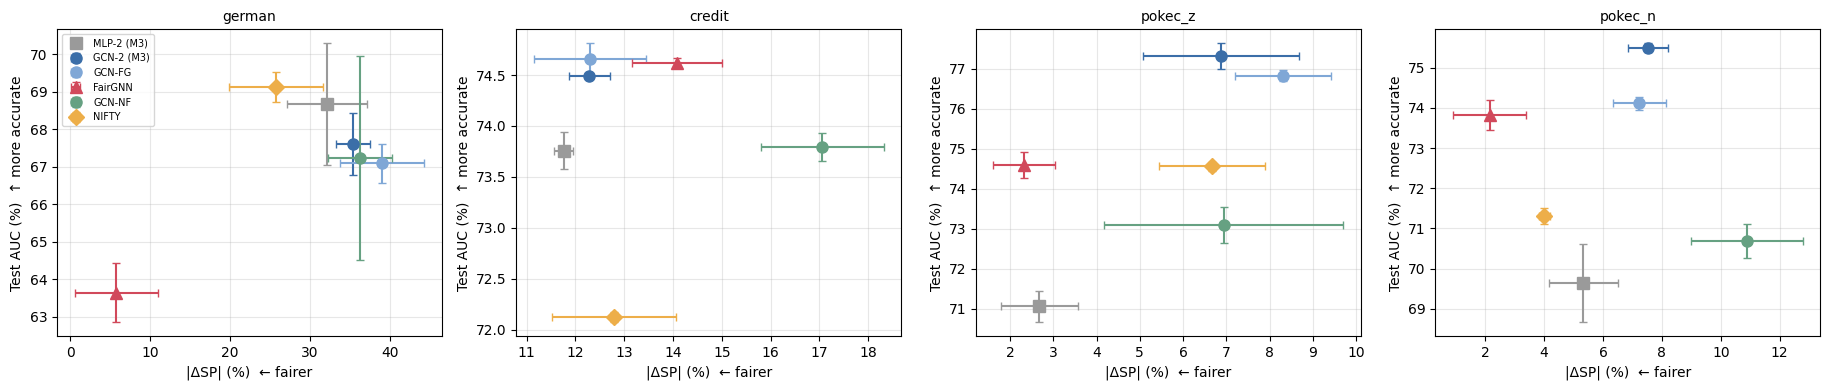

In [16]:
import matplotlib.pyplot as plt

def label_gap(d):
    X, y, s, A, tr, va, te, _ = data[d]
    return y[te][s[te] == 1].mean() - y[te][s[te] == 0].mean()

m3 = pd.read_csv(f'{RESULTS_DIR}/m3_results_v4.csv')
m3 = m3[m3.model.eq('MLP') & m3.K.eq(2) | m3.model.eq('GCN') & m3.K.eq(2)].copy()
m3['method'] = m3.model + '-2 (M3)'
ours = pd.concat([m3, m4[m4.selection == 'ours']], ignore_index=True)
ours = ours[ours.dataset.isin(M4_DATASETS)]
ours['excess_sp_tuned'] = ours.sp_signed_tuned - ours.dataset.map({d: label_gap(d) for d in M4_DATASETS})
order = ['MLP-2 (M3)', 'GCN-2 (M3)', 'GCN-FG', 'FairGNN', 'GCN-NF', 'NIFTY']
cols = ['auc', 'balacc_tuned', 'f1_tuned', 'sp_signed_tuned', 'excess_sp_tuned', 'eo_signed_tuned',
        'score_sens_auc', 'cf_tuned', 'instab_tuned']
g = ours.groupby(['dataset', 'method'])[cols]
main = ((g.mean() * 100).round(1).astype(str) + ' ± ' + (g.std() * 100).round(1).astype(str))
main = main.reindex(pd.MultiIndex.from_product([M4_DATASETS, order]))
main.to_csv(f'{RESULTS_DIR}/m4_main_table.csv')
print(main.to_string())

def paired_diff(d, cfg_a, cfg_b, seeds=range(5), n_boot=1000):
    """Paired bootstrap over the SAME test nodes: (b - a) in |dSP|, |dEO| and AUC, pooled over seeds, in %."""
    X, y, s, A, tr, va, te, _ = data[d]
    yt, st = y[te], s[te]
    def load(cfg, sd):
        p = np.load(f'{RESULTS_DIR}/probs/{d}_{cfg}_s{sd}.npy')
        return p[te], (p[te] >= pick_threshold(p[va], y[va])).astype(int)
    rng, D = np.random.RandomState(0), []
    for sd in seeds:
        (pa, ya), (pb, yb) = load(cfg_a, sd), load(cfg_b, sd)
        for _ in range(n_boot // len(seeds)):
            b = rng.randint(0, len(te), len(te))
            ga, gb = group_gaps(yt[b], ya[b], st[b]), group_gaps(yt[b], yb[b], st[b])
            D.append([abs(gb[0]) - abs(ga[0]), abs(gb[1]) - abs(ga[1]),
                      roc_auc_score(yt[b], pb[b]) - roc_auc_score(yt[b], pa[b])])
    D = 100 * np.array(D)
    out = {}
    for j, k in enumerate(['dSP', 'dEO', 'AUC']):
        lo, hi = np.percentile(D[:, j], [2.5, 97.5])
        out[k] = f"{D[:, j].mean():+.1f} [{lo:+.1f},{hi:+.1f}]{'*' if lo > 0 or hi < 0 else ''}"
    return out

PAIRS = [('GCN-FG-ours', 'FairGNN-ours', 'FairGNN vs its own GCN'),
         ('GCN-NF-ours', 'NIFTY-ours',   'NIFTY vs its own GCN'),
         ('GCN2',        'FairGNN-ours', 'FairGNN vs M3 GCN-2'),
         ('GCN2',        'NIFTY-ours',   'NIFTY vs M3 GCN-2')]
prow = []
for d in M4_DATASETS:
    for a, b, label in PAIRS:
        prow.append(dict(dataset=d, comparison=label, **paired_diff(d, a, b)))
paired4 = pd.DataFrame(prow)
paired4.to_csv(f'{RESULTS_DIR}/m4_paired_tests.csv', index=False)
print('\nNegative dSP/dEO = method B is FAIRER than A; negative AUC = B less accurate. * = 95% CI excludes 0')
print(paired4.to_string(index=False))

# Figure: fairness-accuracy trade-off (one panel per dataset)
mk = {'MLP-2 (M3)': ('s', '#9a9a9a'), 'GCN-2 (M3)': ('o', '#3b6ea8'), 'GCN-FG': ('o', '#7fa7d6'),
      'FairGNN': ('^', '#d1495b'), 'GCN-NF': ('o', '#66a182'), 'NIFTY': ('D', '#edae49')}
ours['abs_dsp'] = ours.sp_signed_tuned.abs() * 100
ours['auc100'] = ours.auc * 100
fig, axes = plt.subplots(1, len(M4_DATASETS), figsize=(4.6 * len(M4_DATASETS), 4), squeeze=False)
for j, d in enumerate(M4_DATASETS):
    ax = axes[0, j]
    for meth in order:
        sub = ours[(ours.dataset == d) & (ours.method == meth)]
        if sub.empty:
            continue
        m_, c_ = mk[meth]
        ax.errorbar(sub.abs_dsp.mean(), sub.auc100.mean(), xerr=sub.abs_dsp.std(), yerr=sub.auc100.std(),
                    fmt=m_, color=c_, ms=8, capsize=3, label=meth)
    ax.set_title(d, fontsize=10); ax.set_xlabel('|ΔSP| (%)  ← fairer'); ax.set_ylabel('Test AUC (%)  ↑ more accurate')
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/m4_tradeoff.png', dpi=200); plt.show()